### Step 1: Load and Explore the German Credit Dataset

In [1]:
import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv('/content/german_credit_data.csv')

# Display basic information and first few rows
print("Dataset Shape:", df.shape)
print("\nMissing Values Summary:")
print(df.isnull().sum())
display(df.head())

Dataset Shape: (1000, 11)

Missing Values Summary:
Unnamed: 0            0
Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
Risk                  0
dtype: int64


,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,4,53,male,2,free,little,little,4870,24,car,bad


### Step 2: Data Preprocessing
We will handle missing values, encode the categorical variables, and define our target variable (`Risk`).

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Handle missing values for categorical columns (e.g., Saving accounts, Checking account)
df['Saving accounts'] = df['Saving accounts'].fillna('Unknown')
df['Checking account'] = df['Checking account'].fillna('Unknown')

# Drop any index column if present (often German credit data has an unnamed ID column)
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# Encode categorical variables
cat_cols = df.select_dtypes(include=['object']).columns
le_dict = {}

for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    le_dict[col] = le

# Define Features (X) and Target (y)
# Usually the target column indicating good/bad status is named 'Risk'
if 'Risk' in df.columns:
    X = df.drop(columns=['Risk'])
    y = df['Risk']
else:
    # Fallback to the last column if 'Risk' is named differently
    X = df.iloc[:, :-1]
    y = df.iloc[:, -1]

# Split into training and test sets (80/20 split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Features shape:", X_train.shape)
print("Target distribution in training set:\n", y_train.value_counts())

Features shape: (800, 9)
Target distribution in training set:
 Risk
1    560
0    240
Name: count, dtype: int64


### Step 3: Train Classifier & Evaluate with Confusion Matrix

Model Accuracy: 0.7450

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.43      0.50        60
           1       0.78      0.88      0.83       140

    accuracy                           0.74       200
   macro avg       0.69      0.66      0.67       200
weighted avg       0.73      0.74      0.73       200



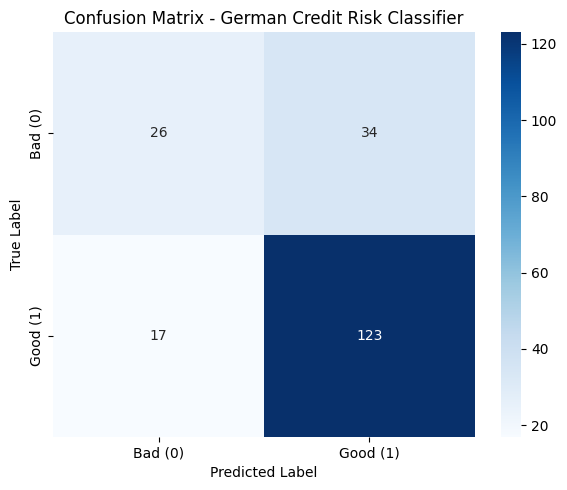

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Initialize and train the Random Forest Classifier
model = RandomForestClassifier(random_state=42, n_estimators=100)
model.fit(X_train, y_train)

# Predict on the test set
y_pred = model.predict(X_test)

# Calculate and print Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Generate and plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Bad (0)', 'Good (1)'] if 'Risk' in le_dict else None,
            yticklabels=['Bad (0)', 'Good (1)'] if 'Risk' in le_dict else None)
plt.title('Confusion Matrix - German Credit Risk Classifier')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()